In [2]:
from torch_geometric.datasets import TUDataset
from torch_geometric.data import DataLoader

In [3]:
dataset = TUDataset(root="TUDataset", name="MUTAG")

In [4]:
import networkx as nx
import matplotlib.pyplot as plt
import torch
def visualize_mutag_graph(G, pos=None, title=None, ax=None, save_path=None):
    atom_colors = {
        'C': '#FDB813',
        'N': '#3776AB',
        'O': '#FF6961',
        'F': '#ADD8E6',
        'I': '#8A2BE2',
        'Cl': '#228B22',
        'Br': '#FF6347'
    }
    atom_types = ['C', 'N', 'O', 'F', 'I', 'Cl', 'Br']
    node_labels = {}
    node_colors = []
    
    for node in G.nodes():

        node_feature = G.nodes[node].get('x') 
        node_feature = torch.tensor(node_feature)
        if node_feature is not None:
            atom_idx = node_feature.argmax().item()  
            atom = atom_types[atom_idx] 
        else:
            atom = 'C' 

        node_labels[node] = f"{node}_{atom}" 
        node_colors.append(atom_colors.get(atom, '#808080'))

    nodes = list(G.nodes())

    if pos is None:
        pos = nx.spring_layout(G, seed=42, iterations=50)

    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 6))
    
    nx.draw(
        G,
        pos=pos,
        node_size=400,
        font_size=9,
        node_color=node_colors,
        nodelist=nodes,
        font_weight='bold',
        ax=ax
    )

    for node in nodes:
        label = node_labels[node]
        x_pos, y_pos = pos[node]
        ax.text(x_pos, y_pos, label, fontsize=8, ha='center', va='center', color='black', fontweight='bold')

    if title:
        ax.set_title(title, fontsize=10, color='black')
    
    ax.axis('off')

    if save_path:
        plt.savefig(save_path, bbox_inches='tight')
        plt.close(fig)
    else:
        plt.show()


In [5]:
import networkx as nx
from torch_geometric.utils.convert import to_networkx
from ged4py import GraphEditDistance

G1 = to_networkx(dataset[0], to_undirected=True, node_attrs="x")
G2 = to_networkx(dataset[7], to_undirected=True, node_attrs="x")
# G2.remove_edge(0,5)

ged = GraphEditDistance(1, 1, 1, 1)  

result = ged.compare([G1, G2], None)
distance = ged.distance(result)
distance, result

(array([[0.  , 0.92],
        [1.  , 0.  ]]),
 array([[ 0., 23.],
        [25.,  0.]]))

In [6]:
from model.gin import *

device = "cuda" if torch.cuda.is_available() else "cpu"
model = GIN(
        in_channels=dataset.num_features,
        hidden_channels=32,
        out_channels=dataset.num_classes,
        num_layers=5,
    ).to(device)
model.load_state_dict(torch.load("model/GIN_mutag.pth"))
model.eval()

GIN(
  (convs): ModuleList(
    (0): GINConv(nn=Sequential(
      (0): Linear(in_features=7, out_features=64, bias=True)
      (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Linear(in_features=64, out_features=32, bias=True)
    ))
    (1-4): 4 x GINConv(nn=Sequential(
      (0): Linear(in_features=32, out_features=64, bias=True)
      (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU()
      (3): Linear(in_features=64, out_features=32, bias=True)
    ))
  )
  (batch_norms): ModuleList(
    (0-4): 5 x BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  )
  (mlp): Sequential(
    (0): Linear(in_features=32, out_features=32, bias=True)
    (1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=32, out_features=2, bias=True)
  )
)

In [181]:
softmax0, embedding0 = model.predict(dataset[8].x, dataset[8].edge_index, None)
softmax0, embedding0

(tensor([[0.6410, 0.3590]], grad_fn=<SoftmaxBackward0>),
 tensor([[ 6.5521,  5.8182,  2.3630,  5.5956,  7.7189,  7.7026,  8.0731, 19.0330,
          12.1133, 14.6750,  6.4841, 14.1813,  1.5557,  2.8341,  1.0157,  0.9746,
           3.0241,  7.3750,  0.9087, 14.7999,  0.5000, 11.6466,  0.5915,  5.9828,
           9.1058,  0.0000,  0.6891,  1.1166,  4.7686,  3.5642,  7.5442, 12.1731]],
        grad_fn=<SumBackward1>))

In [7]:
from torch_geometric.utils import from_networkx
import torch.nn.functional as F

G1 = to_networkx(dataset[4], to_undirected=True, node_attrs="x")
G1.remove_edge(1,4)
G1.remove_node(2,4)
G1.remove_edge(0,2)
data1 = from_networkx(G1)
softmax1, embedding1 = model.predict(data1.x, data1.edge_index, None)
print(softmax1)

NetworkXError: The edge 1-4 is not in the graph

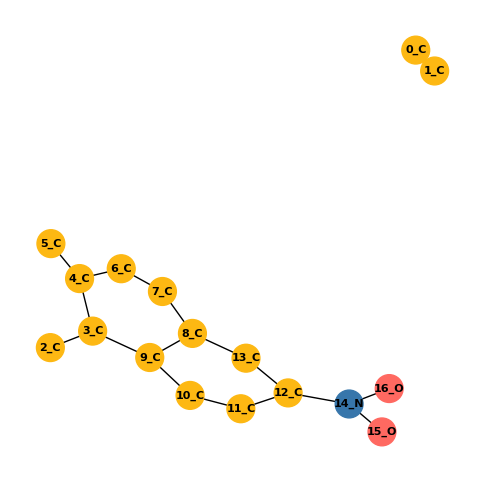

In [14]:
G = to_networkx(data, to_undirected=True, node_attrs="x")
visualize_mutag_graph(G1)

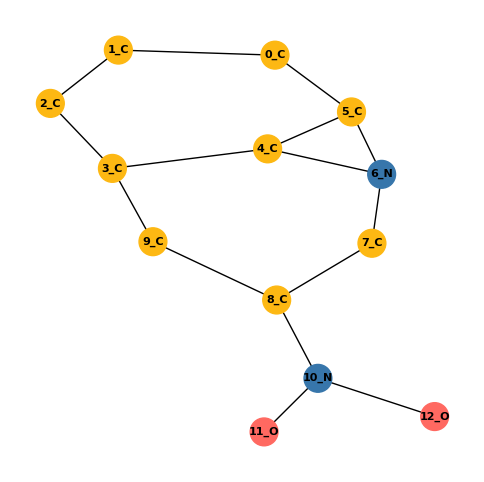

In [37]:
import networkx as nx
import random
import copy

def crossover_graphs(G1, G2):
    G1 = copy.deepcopy(G1)
    G2 = copy.deepcopy(G2)
    
    nodes1 = list(G1.nodes)
    nodes2 = list(G2.nodes)

    cut1 = random.choice(range(1, len(nodes1)))
    cut2 = random.choice(range(1, len(nodes2)))

    part1 = nodes1[:cut1]  

    part2 = nodes2[cut2:] 
    child = nx.Graph()

    child.add_nodes_from((n, G1.nodes[n]) for n in part1)
    child.add_nodes_from((n, G2.nodes[n]) for n in part2)

    child.add_edges_from((u, v) for u, v in G1.edges if u in part1 and v in part1)
    child.add_edges_from((u, v) for u, v in G2.edges if u in part2 and v in part2)

    return child

G1 = to_networkx(dataset[0], to_undirected=True, node_attrs="x")
G2 = to_networkx(dataset[1], to_undirected=True, node_attrs="x")
child = crossover_graphs(G1, G2)

visualize_mutag_graph(child)



In [39]:
import shutil
print(shutil.which("dot"))


/opt/homebrew/bin/dot


In [17]:
def visualize_mutag_graph(G, pos=None, title=None, ax=None, save_path=None,
                          important_edges=None, important_nodes=None):
    import matplotlib.pyplot as plt
    import torch

    atom_colors = {
        'C': '#FDB813',
        'N': '#3776AB',
        'O': '#FF6961',
        'F': '#ADD8E6',
        'I': '#8A2BE2',
        'Cl': '#228B22',
        'Br': '#FF6347'
    }
    atom_types = ['C', 'N', 'O', 'F', 'I', 'Cl', 'Br']
    node_labels = {}
    node_colors = []
    node_border_colors = []
    node_border_widths = []

    important_nodes = set(important_nodes) if important_nodes else set()
    important_edges = set(important_edges) if important_edges else set()
    print(important_edges)
    for node in G.nodes():
        node_feature = G.nodes[node].get('x')
        node_feature = torch.tensor(node_feature)
        if node_feature is not None:
            atom_idx = node_feature.argmax().item()
            atom = atom_types[atom_idx]
        else:
            atom = 'C'
        node_labels[node] = f"{node}_{atom}"
        node_colors.append(atom_colors.get(atom, '#808080'))

        # Viền đậm nếu là node quan trọng
        if f"nL_{node}" in important_nodes:
            node_border_colors.append("black")
            node_border_widths.append(2.5)
        else:
            node_border_colors.append("gray")
            node_border_widths.append(0.5)

    if pos is None:
        pos = nx.spring_layout(G, seed=42, iterations=50)

    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 6))

    nx.draw_networkx_nodes(
        G, pos,
        node_color=node_colors,
        edgecolors=node_border_colors,
        linewidths=node_border_widths,
        node_size=400,
        ax=ax
    )

    # Xử lý viền đậm cho edge
    edge_colors = []
    edge_widths = []
    for u, v in G.edges():
        edge = tuple(sorted((u, v)))
        if f"n{edge[0]}_n{edge[1]}" in important_edges:
            edge_colors.append("black")
            edge_widths.append(2.5)
        else:
            edge_colors.append("gray")
            edge_widths.append(0.5)

    nx.draw_networkx_edges(
        G, pos,
        width=edge_widths,
        edge_color=edge_colors,
        ax=ax
    )

    nx.draw_networkx_labels(G, pos, labels=node_labels, font_size=8, font_weight='bold', ax=ax)

    if title:
        ax.set_title(title, fontsize=10, color='black')

    ax.axis('off')

    if save_path:
        plt.savefig(save_path, bbox_inches='tight')
        plt.close(fig)
    else:
        plt.show()

{'n3_n9', 'n0_n5', 'n8_n13', 'n14_n15'}


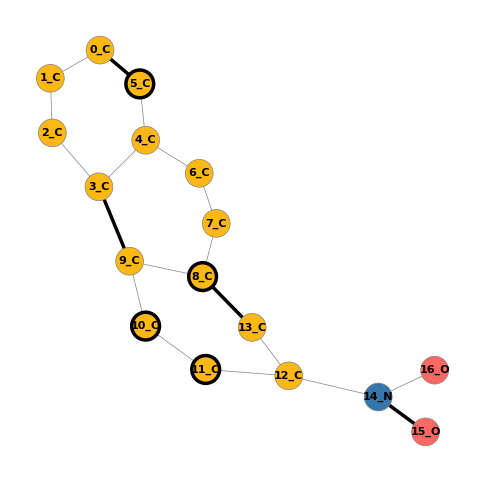

### EVALUATION WITH METRICS ###

In [ ]:
def is_satisfied(G, rule, node_type=None):
    for key, cond in rule.items():
        if key.startswith('nL_'):
            node_id = int(key[3:])
            if node_id not in G.nodes:
                return False
            node_label = torch.tensor(G.nodes[node_id]['x'])
            node_label = node_type[node_label.argmax().item()] if node_label is not None else None
            if node_label != cond:
                return False
        elif '_' in key:
            n1, n2 = key.split('_')
            node_id1 = int(n1[1:])
            node_id2 = int(n2[1:])
            if not G.has_edge(node_id1, node_id2):
                return False
    return True


In [ ]:
import random
def mask(G, rule):
    feature_dim = len(G.nodes[0].get('x')) if G.nodes else 0
    G_maskeout = G.copy()
    G_mask = nx.Graph()
    for key, cond in rule.items():
        if '_' in key and not key.startswith('nL_'): # edge
            u, v = key.split('_')
            u, v = int(u[1:]), int(v[1:])
            if cond == '>0':
                if not G_mask.has_edge(u, v):
                    if not G_mask.has_node(u) and G.has_node(u):
                        attrs = G.nodes[u]
                        G_mask.add_node(u, **attrs)
                    if not G_mask.has_node(v) and G.has_node(v):
                        attrs = G.nodes[v]
                        G_mask.add_node(v, **attrs)
                    G_mask.add_edge(u, v)
                
                if G_maskeout.has_edge(u, v):
                    G_maskeout.remove_edge(u, v)
                    print(f"Removed edge {u}-{v} with condition {cond}")
            elif cond == '<=0':
                if not G_maskeout.has_edge(u, v):
                    if not G_maskeout.has_node(u):
                        new_feature = torch.zeros(feature_dim, dtype=torch.float)
                        node_label = random.choice(range(feature_dim))
                        new_feature[node_label] = 1
                        G_maskeout.add_node(u, x=new_feature)
                    if not G_maskeout.has_node(v):
                        new_feature = torch.zeros(feature_dim, dtype=torch.float)
                        node_label = random.choice(range(feature_dim))
                        new_feature[node_label] = 1
                        G_maskeout.add_node(v, x=new_feature)
                    G_maskeout.add_edge(u, v)

        elif key.startswith('nL_'): # node label
            node_id = int(key.split('_')[1])
            if cond != 'None':
                if G_maskeout.has_node(node_id):
                    G_maskeout.remove_node(node_id)
                    print(f"Removed node {node_id} with label {cond}")
                if not G_mask.has_node(node_id) and G.has_node(node_id):
                    attrs = G.nodes[node_id]
                    G_mask.add_node(node_id, **attrs)
                    print(f"Added node {node_id} with label {cond}")
            else:
                if not G_maskeout.has_node(node_id):
                    new_feature = torch.zeros(feature_dim, dtype=torch.float)
                    node_label = random.choice(range(feature_dim))
                    new_feature[node_label] = 1
                    G_maskeout.add_node(node_id, x=new_feature)
                    print(f"Added node {node_id} with label {node_label}")
    return G_maskeout, G_mask

Removed edge 6-7 with condition >0
Removed node 6 with label N


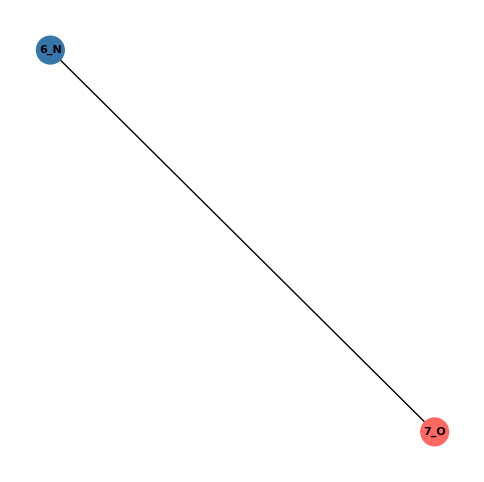

In [ ]:
G = to_networkx(dataset[115], to_undirected=True, node_attrs="x")
rule = {'n1_n5': '<=0', 'n1_n3': '<=0', 'n2_n5': '<=0', 'n3_n5': '<=0', 'nL_0': 'C', 'n9_n10': '<=0', 'n3_n9': '>0'}
G_maskout, G_mask = mask(G, rule)
visualize_mutag_graph(G_mask)

In [12]:
def evaluate(model, graph, rule, device='cpu'):
    G = to_networkx(graph, to_undirected=True, node_attrs="x")
    prob, embedding = model.predict(graph.x, graph.edge_index, None)
    prob = prob.squeeze(0) 
    print(f"Probabilities: {prob}")
    target_class = torch.argmax(prob).item()  
    conf_target = prob[target_class].item()
    
    
    G_maskout, G_mask = mask(G, rule)
    
    g_maskout = from_networkx(G_maskout)
    prob_maskout, embedding_maskout = model.predict(g_maskout.x, g_maskout.edge_index, None)
    prob_maskout = prob_maskout.squeeze(0) 
    print(f"Probabilities after perturbation: {prob_maskout}")
    conf_maskout = prob_maskout[target_class].item()
    
    fidelity = conf_target - conf_maskout
    
    if G_mask.number_of_nodes() < 1:
        return fidelity, 1
    g_mask = from_networkx(G_mask)
    prob_mask, embedding_mask = model.predict(g_mask.x, g_mask.edge_index, None)
    prob_mask = prob_mask.squeeze(0)
    print(f"Probabilities of masked graph: {prob_mask}")
    conf_mask = prob_mask[target_class].item()
    
    inv_fidelity = conf_target - conf_mask

    total_nodes = G.number_of_nodes()
    explained_nodes = G_mask.number_of_nodes()
    sparsity = 1 - (explained_nodes / total_nodes)

    return fidelity, inv_fidelity, sparsity


In [294]:
fid, inv_fid, sp = evaluate(model, dataset[115], rule, device=device)
print(f"Average Fidelity: {fid:.4f}, Inverse Fidelity: {inv_fid:.4f}, Sparsity: {sp:.4f}")

Probabilities: tensor([0.9818, 0.0182], grad_fn=<SqueezeBackward1>)
Removed edge 6-7 with condition >0
Removed node 6 with label N
Probabilities after perturbation: tensor([0.0732, 0.9268], grad_fn=<SqueezeBackward1>)
Probabilities of masked graph: tensor([0.9960, 0.0040], grad_fn=<SqueezeBackward1>)
Average Fidelity: 0.9086, Inverse Fidelity: -0.0142, Sparsity: 0.8000


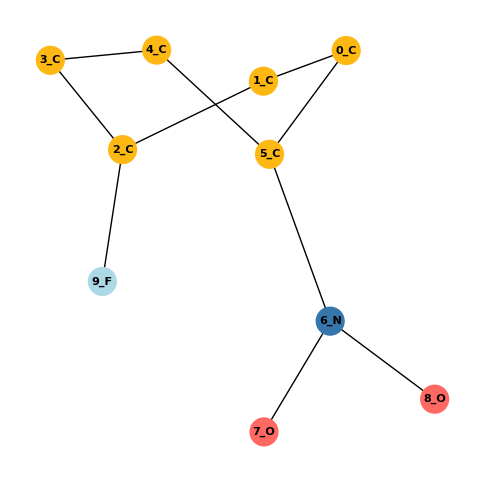

In [295]:
visualize_mutag_graph(G)

In [10]:
from torch.utils.data import Subset
from torch_geometric.datasets import BA2MotifDataset

dataset = TUDataset(root="TUDataset", name="MUTAG")
with open('datasets/MUTAG_splits.pkl', 'rb') as f:
    split_indices = pickle.load(f)
test_idx = split_indices['test_idx']
test_dataset = [dataset[i] for i in test_idx]

tensor([0])
{'n2_n7', 'n6_n11', 'n0_n7', 'n6_n10', 'n4_n6', 'n6_n13', 'n8_n13', 'n9_n11', 'n9_n14', 'n13_n14', 'n4_n9'}


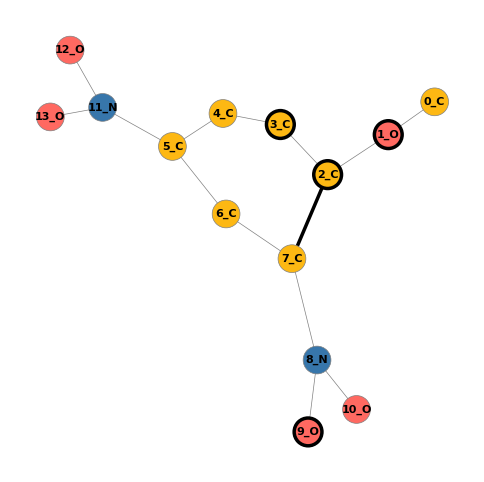

In [ ]:
index = 3
G = to_networkx(test_dataset[index], to_undirected=True, node_attrs="x")
print(test_dataset[index].y)

r = {'n4_n6': '<=0', 'n8_n13': '<=0', 'n9_n11': '<=0', 'n6_n11': '<=0', 'n0_n7': '<=0', 'n4_n9': '<=0', 'nL_15': 'None', 'n6_n13': '<=0', 'nL_2': 'C', 'nL_3': 'C', 'nL_9': 'O', 'nL_1': 'O', 'n6_n10': '<=0', 'n13_n14': '<=0', 'n9_n14': '<=0', 'n2_n7': '>0'}
important_nodes = [k for k in r if k.startswith('nL_')]
important_edges = [k for k in r if k.startswith('n') and '_n' in k]
visualize_mutag_graph(G, important_edges=important_edges, important_nodes=important_nodes)
